# PBI-02 · EDA – find data issues in the SP-buy base data
**Owner:** Jian Rong · **Sprint 1** · Group 3 · ST1519 Agile MLOps CA1

**Goal (user story):** explore `customers_base`, `orders_base` and `labels_base` and find every data issue that could hurt a fraud-detection model.
**Output:** (1) this notebook, (2) figures in `notebooks/figures/`, (3) the data-issue log `docs/data_issue_log.csv` (PBI-02.5) which is the input to PBI-03 (`cleaning.py`) and PBI-04 (`transform.py`).

| Sub-task | Section |
|---|---|
| PBI-02.1 shapes, dtypes, missing, duplicates | 1 |
| PBI-02.2 inconsistent categories | 2 |
| PBI-02.3 distributions, outliers, skew (+ dates) | 3 |
| PBI-02.4 fraud class balance, join coverage | 4 |
| PBI-02.5 data-issue log | 5 |

**Design rule:** this notebook only *reads* and *measures*. Nothing is overwritten – every issue is logged with a count, and the fix is implemented later in `cleaning.py` (PBI-03).

## 0 · Setup

In [1]:
import os, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Paths: repo layout is data/, notebooks/, docs/. Override with env vars if yours differs.
DATA_DIR = Path(os.environ.get("CA1_DATA_DIR", "../data"))
FIG_DIR  = Path(os.environ.get("CA1_FIG_DIR",  "figures"))
DOCS_DIR = Path(os.environ.get("CA1_DOCS_DIR", "../docs"))
for d in (FIG_DIR, DOCS_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
PLOT_SAMPLE = 200_000   # plot at most this many rows (keeps charts fast, shape is unchanged)

FILES = {"customers": "customers_base.csv", "orders": "orders_base.csv", "labels": "labels_base.csv"}
EXPECTED = {
    "customers": ["country_code", "customer_id", "mobile_verified", "num_orders_last_50days",
                  "num_cancelled_orders_last_50days", "num_refund_orders_last_50days",
                  "total_payment_last_50days", "num_associated_customers", "first_order_datetime"],
    "orders":    ["country_code", "order_id", "collect_type", "payment_method", "order_value",
                  "num_items_ordered", "refund_value", "order_date"],
    "labels":    ["country_code", "order_id", "customer_id", "is_fraud"],
}
NUMERIC = {
    "customers": ["num_orders_last_50days", "num_cancelled_orders_last_50days", "num_refund_orders_last_50days",
                  "total_payment_last_50days", "num_associated_customers"],
    "orders":    ["order_value", "num_items_ordered", "refund_value"],
}

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---- the issue log: one row per issue, filled automatically by the checks below ----
ISSUES = {}
def log_issue(issue, table, column, count, total, fix, ml_impact, severity="Medium"):
    """Re-running a cell overwrites the same row instead of duplicating it."""
    ISSUES[(table, column, issue)] = dict(
        issue=issue, table=table, column=column, count=int(count), total_rows=int(total),
        pct=round(100 * count / total, 4) if total else np.nan,
        proposed_fix=fix, ml_impact=ml_impact, severity=severity)

## 1 · PBI-02.1 – Load, shapes, dtypes, missing values, duplicates

**Why load everything as text (`dtype=str`)?** If pandas guesses types, a single bad token (`"N/A"`, `"1,200"`) silently turns a whole numeric column into `object`, or `"True"/"1"/"yes"` mixtures get hidden. Reading as text lets us *count* every non-conforming value ourselves, then convert deliberately.
`keep_default_na=False, na_values=[""]` means only truly empty cells become NaN; tokens like `"NA"` or `"null"` stay visible so we can count them as *placeholder* values.

In [2]:
def load_raw(table):
    df = pd.read_csv(DATA_DIR / FILES[table], dtype=str, keep_default_na=False, na_values=[""])
    stripped = df.columns.str.strip()
    if (stripped != df.columns).any():
        print(f"  ! {table}: column names had stray whitespace -> stripped")
    df.columns = stripped
    return df

raw = {t: load_raw(t) for t in FILES}

# schema check against the spec (Appendix A1)
for t, df in raw.items():
    missing_cols = [c for c in EXPECTED[t] if c not in df.columns]
    extra_cols   = [c for c in df.columns if c not in EXPECTED[t]]
    print(f"{t:10s} columns OK" if not (missing_cols or extra_cols)
          else f"{t:10s} MISSING={missing_cols} EXTRA={extra_cols}")
    if missing_cols:
        log_issue("Expected column missing from file", t, ",".join(missing_cols), len(missing_cols),
                  len(EXPECTED[t]), "ETL must fail with a clear error", "Pipeline would break", "High")

shape_tbl = pd.DataFrame({
    "rows": {t: len(df) for t, df in raw.items()},
    "cols": {t: df.shape[1] for t, df in raw.items()},
    "memory_MB": {t: df.memory_usage(deep=True).sum() / 1e6 for t, df in raw.items()},
})
shape_tbl

customers  columns OK
orders     columns OK
labels     columns OK


,rows,cols,memory_MB
customers,901312,9,448.264
orders,949889,8,437.597
labels,950318,4,208.120


In [3]:
for t, df in raw.items():
    print(f"\n=== {t} : first 5 rows ===")
    display(df.head())


=== customers : first 5 rows ===


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,PK,c238e72e73,True,2,1,0,13.190387354705049,1,2021-03-23 09:16:29
1,MY,d1f64e8f1c,True,8,0,0,41.76343740385339,1,2020-12-01 04:46:26
2,PH,e0fae59ece,True,3,0,0,44.09307870065593,2,2019-02-13 05:56:40
3,PK,09af521b9f,True,61,0,1,4925.383520076438,7,2020-09-08 08:18:39
4,MY,779dacab15,True,7,0,0,92.42875510570114,1,2021-02-19 09:59:16



=== orders : first 5 rows ===


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
0,PH,c285aa06a5,Delivery,antfinancial gcash,5.387818896776103,4.0,0.0,2023/04/09
1,PH,4cd8384425,Delivery,antfinancial gcash,7.452310249746387,6.0,0.0,2023/04/09
2,PH,aa42f97d2e,Delivery,credit card,15.588588163180082,6.0,0.0,2023/04/09
3,PH,f3523e5896,Delivery,credit card,90.468360914714,70.0,0.0,2023/04/09
4,PH,5ac770f990,Delivery,payment on Delivery,8.12368955152534,6.0,0.88,2023/04/09



=== labels : first 5 rows ===


,country_code,order_id,customer_id,is_fraud
0,TH,b9ce4cdead,4a2deee064,0
1,MY,eae640c3dd,0e39f85e6d,0
2,PH,6b5eff4d8f,b88034bb7a,0
3,MY,31928238a7,b24be37d24,0
4,MY,4adec8e335,996287540f,0


### 1a · Missing values (true NaN, whitespace-only, and placeholder tokens like `N/A`)

,table,column,nan,blank,placeholder,total_missing,pct
8,customers,first_order_datetime,712,0,0,712,0.079
12,orders,payment_method,21501,0,0,21501,2.264
14,orders,num_items_ordered,1,0,0,1,0.000


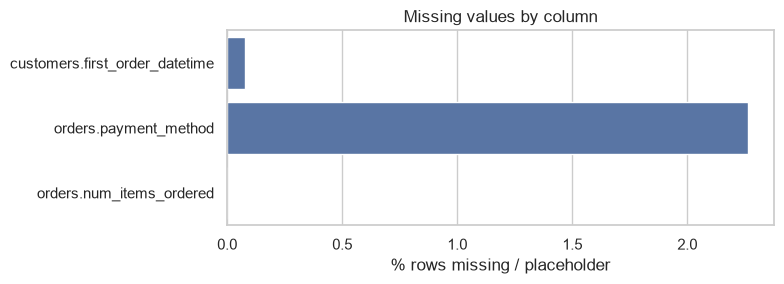

In [4]:
PLACEHOLDERS = {"na", "n/a", "nan", "null", "none", "?", "-", "--", "unknown", "undefined", "missing"}

def missing_report(df, table):
    n, rows = len(df), []
    for c in df.columns:
        s = df[c]
        nan = int(s.isna().sum())
        blank = int(s.str.strip().eq("").sum())
        ph = int(s.dropna().str.strip().str.lower().isin(PLACEHOLDERS).sum())
        total = nan + blank + ph
        rows.append(dict(table=table, column=c, nan=nan, blank=blank, placeholder=ph,
                         total_missing=total, pct=100 * total / n))
        if total:
            log_issue("Missing / placeholder values", table, c, total, n,
                      "Store as NULL (None) per docs/rds-schema.md; handle in PBI-04 with a missing-flag feature or an imputer fitted on the training split only",
                      "Most sklearn/XGBoost-sklearn models fail on NaN; missingness itself may be a fraud signal",
                      "High" if 100 * total / n > 5 else "Medium")
    return pd.DataFrame(rows)

missing_all = pd.concat([missing_report(df, t) for t, df in raw.items()], ignore_index=True)
display(missing_all[missing_all.total_missing > 0] if (missing_all.total_missing > 0).any()
        else pd.DataFrame({"result": ["No missing values found in any table"]}))

plot_m = missing_all[missing_all.total_missing > 0]
if len(plot_m):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(plot_m) + 1.5))
    sns.barplot(data=plot_m, y=plot_m.table + "." + plot_m.column, x="pct", color="#4C72B0", ax=ax)
    ax.set_xlabel("% rows missing / placeholder"); ax.set_ylabel(""); ax.set_title("Missing values by column")
    savefig("01_missing_values")

### 1b · Duplicates – full-row duplicates, key duplicates, and whitespace in IDs
A **key** must identify one row. We normalise `country_code` (strip + upper-case) *before* testing, because `ph` and `PH` are the same country and otherwise hide real duplicates.

In [5]:
for t, df in raw.items():
    df["cc"] = df["country_code"].str.strip().str.upper()      # normalised country, used for keys & joins

KEYS = {"customers": "customer_id", "orders": "order_id", "labels": "order_id"}
rows = []
for t, df in raw.items():
    n = len(df)
    full_dup = int(df.drop(columns="cc").duplicated().sum())
    idc = KEYS[t]
    id_dup_rows = int(df[idc].duplicated(keep=False).sum())          # rows sharing an id (ignoring country)
    comp_dup = int(df.duplicated(["cc", idc]).sum())                  # extra copies of (country, id)
    ws = int((df[idc].dropna() != df[idc].dropna().str.strip()).sum())
    rows.append(dict(table=t, rows=n, full_row_duplicates=full_dup,
                     rows_sharing_id_only=id_dup_rows, extra_rows_on_country_plus_id=comp_dup,
                     ids_with_whitespace=ws))
    if full_dup:
        log_issue("Exact duplicate rows", t, "(all columns)", full_dup, n,
                  "drop_duplicates()", "Duplicated rows inflate counts and leak between train/test", "Medium")
    if comp_dup:
        log_issue("Duplicate primary key (country_code + id) with differing/same content", t, f"country_code+{idc}",
                  comp_dup, n, "Keep one row per key (latest / first) – decide rule in cleaning.py",
                  "Joins fan out and double-count rows", "High")
    if id_dup_rows and not comp_dup:
        log_issue(f"{idc} is NOT globally unique (collides across countries)", t, idc, id_dup_rows, n,
                  f"Use (country_code, {idc}) as the key in every join / DB primary key",
                  "Joining on the id alone attaches the wrong order/customer to a row", "High")
    if ws:
        log_issue("Whitespace around ID values", t, idc, ws, n, "str.strip() on all id columns",
                  "Silent join misses", "Medium")
pd.DataFrame(rows).set_index("table")

,rows,full_row_duplicates,rows_sharing_id_only,extra_rows_on_country_plus_id,ids_with_whitespace
table,,,,,
customers,901312,0,0,0,0
orders,949889,0,6,0,0
labels,950318,0,6,0,0


**Reading this table:** `rows_sharing_id_only > 0` but `extra_rows_on_country_plus_id = 0` means the *same id string is reused in different countries* – so `order_id` alone is **not** a primary key; the true key is `(country_code, order_id)`. This matters for the RDS schema (PBI-05) and every join.

## 2 · PBI-02.2 – Inconsistent categories
Categorical columns often hide the same value written several ways (`Delivery`, `delivery `, `DELIVERY`). A model one-hot-encodes each spelling as a *different* category, diluting signal.
Method: (1) look at raw value counts, (2) build a **canonical form** (strip → lower-case → collapse `_`, `-`, spaces) and report any canonical value that has more than one raw spelling.

In [6]:
def canon(s):
    return s.str.strip().str.lower().str.replace(r"[\s_\-]+", " ", regex=True)

def variant_report(df, col, table, show=25, log=True):
    s = df[col]
    vc = s.value_counts(dropna=False)
    print(f"\n##### {table}.{col}  ({s.nunique()} distinct raw values, {s.isna().sum():,} NaN)")
    display(vc.head(show).to_frame("rows"))
    pairs = s.dropna().value_counts().rename_axis("raw").reset_index(name="n")   # distinct values only -> fast
    pairs["canon"] = canon(pairs["raw"])
    g = pairs.groupby("canon").agg(n_spellings=("raw", "nunique"), rows=("n", "sum"),
                                   rows_not_in_main_spelling=("n", lambda x: x.sum() - x.max()),
                                   spellings=("raw", lambda x: list(x)))
    bad = g[g.n_spellings > 1]
    if len(bad):
        display(bad)
    if len(bad) and log:
        log_issue("Inconsistent spellings / case / whitespace of same category", table, col,
                  bad.rows_not_in_main_spelling.sum(), len(df),
                  "Normalise: strip, lower-case, map synonyms to one canonical label",
                  "Same category split into several one-hot columns", "High")
    elif not len(bad):
        print("  -> no spelling variants")
    return vc

CAT_COLS = {"customers": ["country_code", "mobile_verified"],
            "orders": ["country_code", "collect_type", "payment_method"],
            "labels": ["country_code"]}
for t, cols in CAT_COLS.items():
    for c in cols:
        variant_report(raw[t], c, t, log=(c != "country_code"))   # country_code is logged in 2a


##### customers.country_code  (7 distinct raw values, 0 NaN)


,rows
country_code,
MY,339134
PH,289358
PK,151877
TH,72509
BD,48044
pk,225
my,165


,n_spellings,rows,rows_not_in_main_spelling,spellings
canon,,,,
my,2,339299,165,"[MY, my]"
pk,2,152102,225,"[PK, pk]"



##### customers.mobile_verified  (3 distinct raw values, 0 NaN)


,rows
mobile_verified,
True,900681
False,466
yes,165


  -> no spelling variants


... (8 outputs left out)

,n_spellings,rows,rows_not_in_main_spelling,spellings
canon,,,,
online banking,2,124983,103,"[online banking, Online Banking]"
payment on delivery,2,312467,20,"[payment on Delivery, payment on delivery]"



##### labels.country_code  (7 distinct raw values, 0 NaN)


,rows
country_code,
MY,360586
PH,281239
PK,184840
TH,63788
BD,59564
ph,180
my,121


,n_spellings,rows,rows_not_in_main_spelling,spellings
canon,,,,
my,2,360707,121,"[MY, my]"
ph,2,281419,180,"[PH, ph]"


### 2a · `country_code` – valid codes only?

In [7]:
# Valid set = the 5 upper-case 2-letter codes observed in the data (BD, MY, PH, PK, TH). Confirm against the table below.
VALID_COUNTRIES = {"BD", "MY", "PH", "PK", "TH"}

rows = []
for t, df in raw.items():
    s = df["country_code"]
    n = len(df)
    not_upper = int((s.dropna() != s.dropna().str.strip().str.upper()).sum())   # 'ph', ' PH', ...
    invalid   = int((~df["cc"].isin(VALID_COUNTRIES) & df["cc"].notna()).sum()) # still wrong after normalising
    rows.append(dict(table=t, rows=n, not_clean_uppercase=not_upper, invalid_after_normalising=invalid,
                     distinct_after_normalising=sorted(df["cc"].dropna().unique())))
    if not_upper:
        log_issue("country_code not upper-case / has whitespace (e.g. 'ph','my')", t, "country_code", not_upper, n,
                  "str.strip().str.upper()", "Splits one country into two categories; breaks joins on country_code", "High")
    if invalid:
        log_issue("country_code not in the valid country list", t, "country_code", invalid, n,
                  "Set to NaN / drop and log", "Unknown category at inference time", "Medium")
display(pd.DataFrame(rows).set_index("table"))

,rows,not_clean_uppercase,invalid_after_normalising,distinct_after_normalising
table,,,,
customers,901312,390,0,"[BD, MY, PH, PK, TH]"
orders,949889,0,0,"[BD, MY, PH, PK, TH]"
labels,950318,301,0,"[BD, MY, PH, PK, TH]"


### 2b · `mobile_verified` – should be a clean True/False

In [8]:
TRUE_TOKENS  = {"true", "t", "1", "1.0", "yes", "y"}
FALSE_TOKENS = {"false", "f", "0", "0.0", "no", "n"}

mv = raw["customers"]["mobile_verified"]
tok = mv.dropna().str.strip().str.lower()
n_cust = len(mv)
not_literal = int((~mv.dropna().isin(["True", "False"])).sum())
unmappable = int((~tok.isin(TRUE_TOKENS | FALSE_TOKENS)).sum())
print(f"values that are not exactly 'True'/'False': {not_literal:,}   |   cannot be mapped to a boolean at all: {unmappable:,}")
if not_literal:
    log_issue("mobile_verified is not a clean True/False (mixed encodings)", "customers", "mobile_verified",
              not_literal, n_cust, "Map {true,t,1,yes,y}->True, {false,f,0,no,n}->False; others -> NaN",
              "Pandas keeps it as object/str -> encoder errors, or 'true' and 'True' become 2 categories", "High")
if unmappable:
    log_issue("mobile_verified has values that cannot be interpreted", "customers", "mobile_verified",
              unmappable, n_cust, "Set to NaN then impute / use 'unknown' category", "Unknown verification status", "Medium")

values that are not exactly 'True'/'False': 165   |   cannot be mapped to a boolean at all: 0


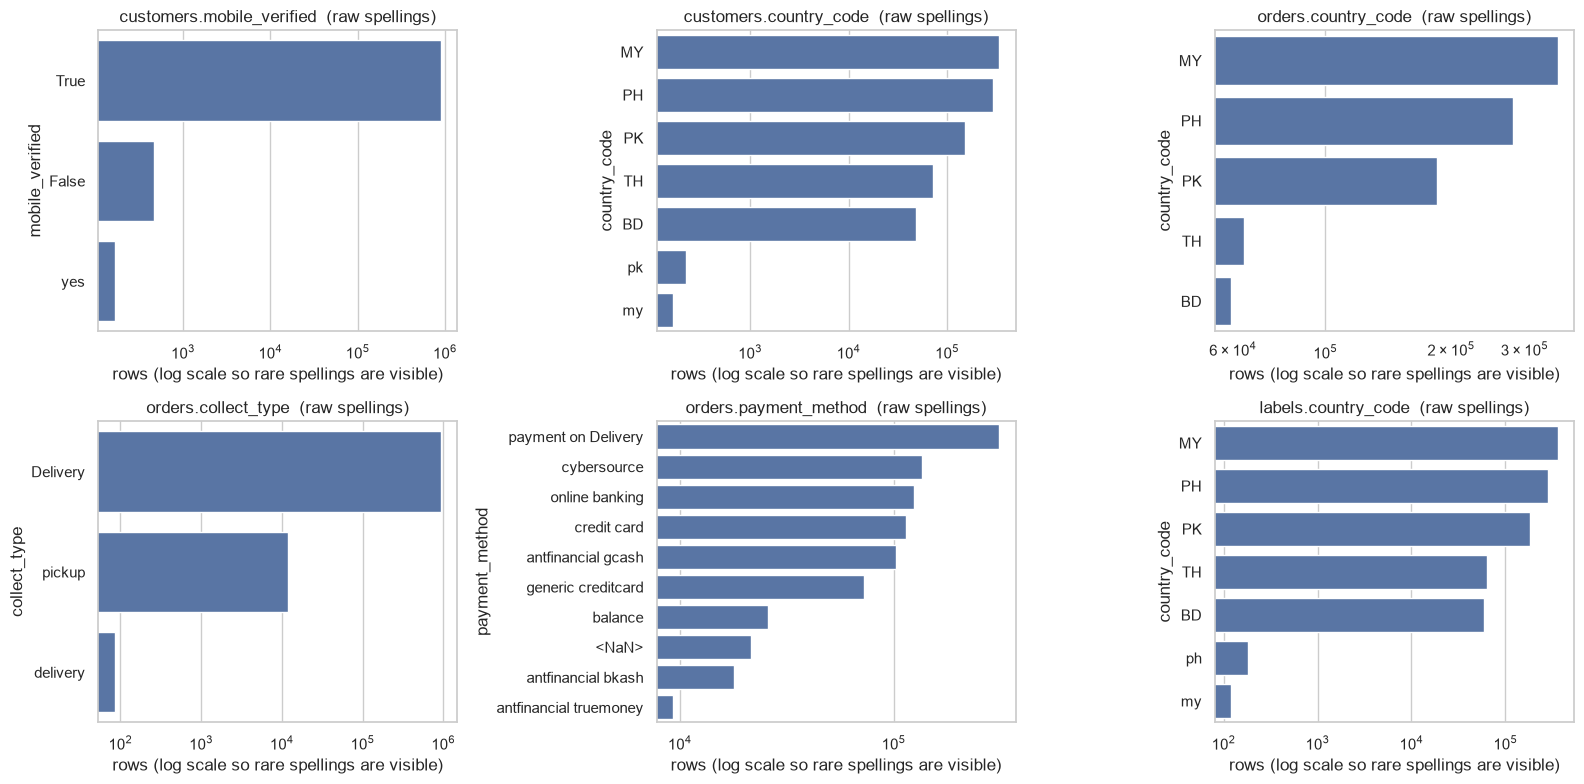

In [9]:
# visual evidence for the category issues (top 8 raw values per column)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (t, c) in zip(axes.ravel(), [("customers", "mobile_verified"), ("customers", "country_code"),
                                      ("orders", "country_code"), ("orders", "collect_type"),
                                      ("orders", "payment_method"), ("labels", "country_code")]):
    vc = raw[t][c].fillna("<NaN>").value_counts().head(10)
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="#4C72B0")
    ax.set_title(f"{t}.{c}  (raw spellings)"); ax.set_xscale("log"); ax.set_xlabel("rows (log scale so rare spellings are visible)")
savefig("02_category_raw_values")

## 3 · PBI-02.3 – Distributions, outliers and skew of numeric columns
Steps: convert text → number **and count what fails**, summary stats (skew, IQR outliers, extreme values), then plots (raw vs `log1p`).
* **Skew** > 1 (or < -1) → long tail. Tree models cope; linear models/distance-based models don't. Fix: `log1p` or cap (winsorise at p99).
* **IQR rule**: outlier if outside `[Q1-1.5·IQR, Q3+1.5·IQR]`. Zero-inflated columns have IQR=0, so *every* non-zero looks like an outlier – for those we also report values `> 5×p99` (really extreme points).

In [10]:
def to_numeric_checked(df, cols, table):
    out = pd.DataFrame(index=df.index)
    for c in cols:
        s = df[c]
        n = pd.to_numeric(s.str.strip(), errors="coerce")
        bad = n.isna() & s.notna()
        if bad.any():
            print(f"  ! {table}.{c}: {bad.sum():,} non-numeric values, e.g. {s[bad].value_counts().head(5).to_dict()}")
            log_issue("Non-numeric text in a numeric column", table, c, bad.sum(), len(df),
                      "pd.to_numeric(errors='coerce') then treat as missing",
                      "Column stays object dtype; model training crashes", "High")
        out[c] = n
    return out

num = {t: to_numeric_checked(raw[t], cols, t) for t, cols in NUMERIC.items()}

In [11]:
def numeric_summary(df, table):
    rows = []
    for c in df.columns:
        x = df[c].dropna()
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        p99 = x.quantile(.99)
        r = dict(table=table, column=c, n=len(x), mean=x.mean(), median=x.median(), std=x.std(),
                 min=x.min(), p99=p99, max=x.max(), skew=x.skew(), pct_zero=100 * (x == 0).mean(),
                 negatives=int((x < 0).sum()),
                 iqr_outliers=int(((x < lo) | (x > hi)).sum()),
                 extreme_gt_5x_p99=int((x > 5 * p99).sum()) if p99 > 0 else 0)
        rows.append(r)
        n_all = len(df)
        if abs(r["skew"]) > 1:
            log_issue(f"Highly skewed distribution (skew={r['skew']:.1f})", table, c, len(x), n_all,
                      "log1p transform (or cap at p99) in transform.py",
                      "Long tail dominates linear/distance-based models and scaling", "Medium")
        if r["negatives"]:
            log_issue("Negative values where only >= 0 makes sense", table, c, r["negatives"], n_all,
                      "Set to NaN (or abs() if confirmed sign error) and log", "Impossible values distort scaling & log transform", "High")
        if r["extreme_gt_5x_p99"]:
            log_issue("Extreme outliers (> 5 x 99th percentile)", table, c, r["extreme_gt_5x_p99"], n_all,
                      "Cap (winsorise) at p99 / p99.9; verify against business rule",
                      "A few points can dominate mean/variance based methods", "Medium")
    return pd.DataFrame(rows)

summary = pd.concat([numeric_summary(num[t], t) for t in num], ignore_index=True)
summary.set_index(["table", "column"])

n    mean  median     std   min       p99        max   skew  pct_zero  negatives  iqr_outliers  extreme_gt_5x_p99
table     column                                                                                                                                                  
customers num_orders_last_50days            901312  21.711  14.000  26.281 0.000   117.000  2,162.000  5.419     6.363          0         53579                 27
          num_cancelled_orders_last_50days  901312   0.264   0.000   1.005 0.000     3.000    259.000 54.999    83.142          0        151945                235
          num_refund_orders_last_50days     901312   0.231   0.000   0.856 0.000     3.000    107.000 17.515    85.757          0        128372                223
          total_payment_last_50days         901312 302.181 164.582 425.801 0.000 1,876.682 42,569.345  8.676     3.729          0         63144                 46
          num_associated_customers          901312   2.685   2.000   6.366 1.000    17.000    101.000 12.479     0.000          0         39178               2802
orders    order_value                       949889   6.938   5.509   6.462 0.000    30.976    662.875  6.620     0.002          0         56798                 36
          num_items_ordered                 949888   3.670   2.000   5.012 1.000    22.000  1,600.000 41.042     0.000          0         69852                 89
          refund_value                      949889   2.236   0.930   3.921 0.000    16.860    518.000  8.410    38.735          0         71069                 53

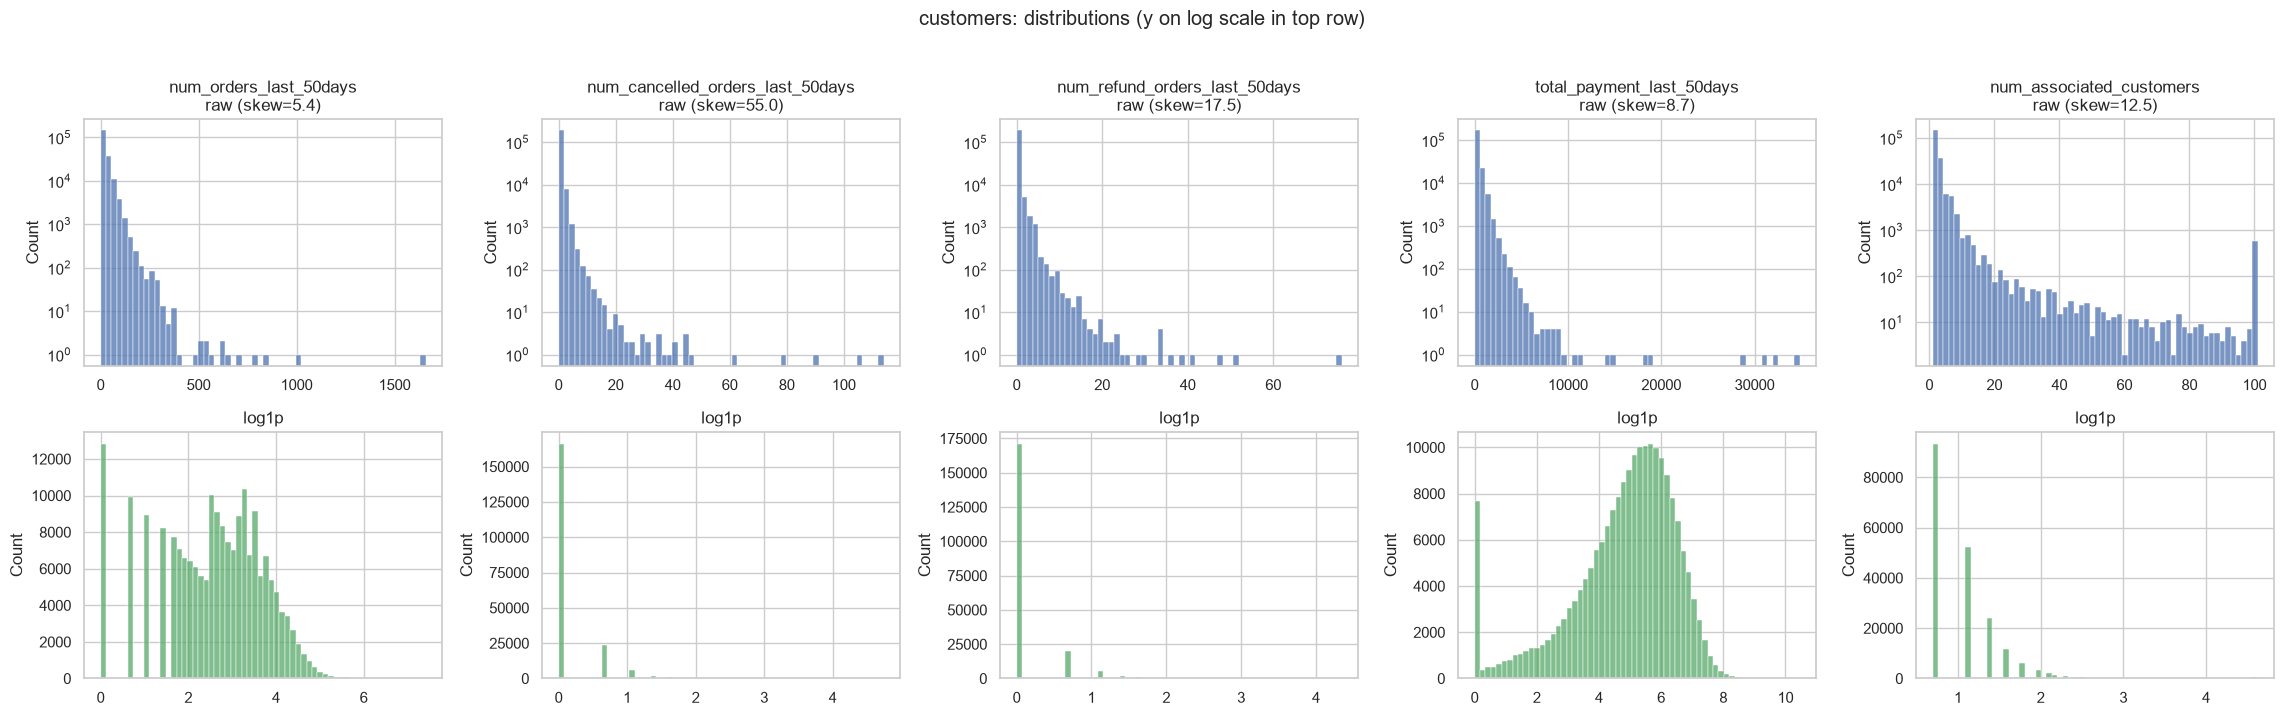

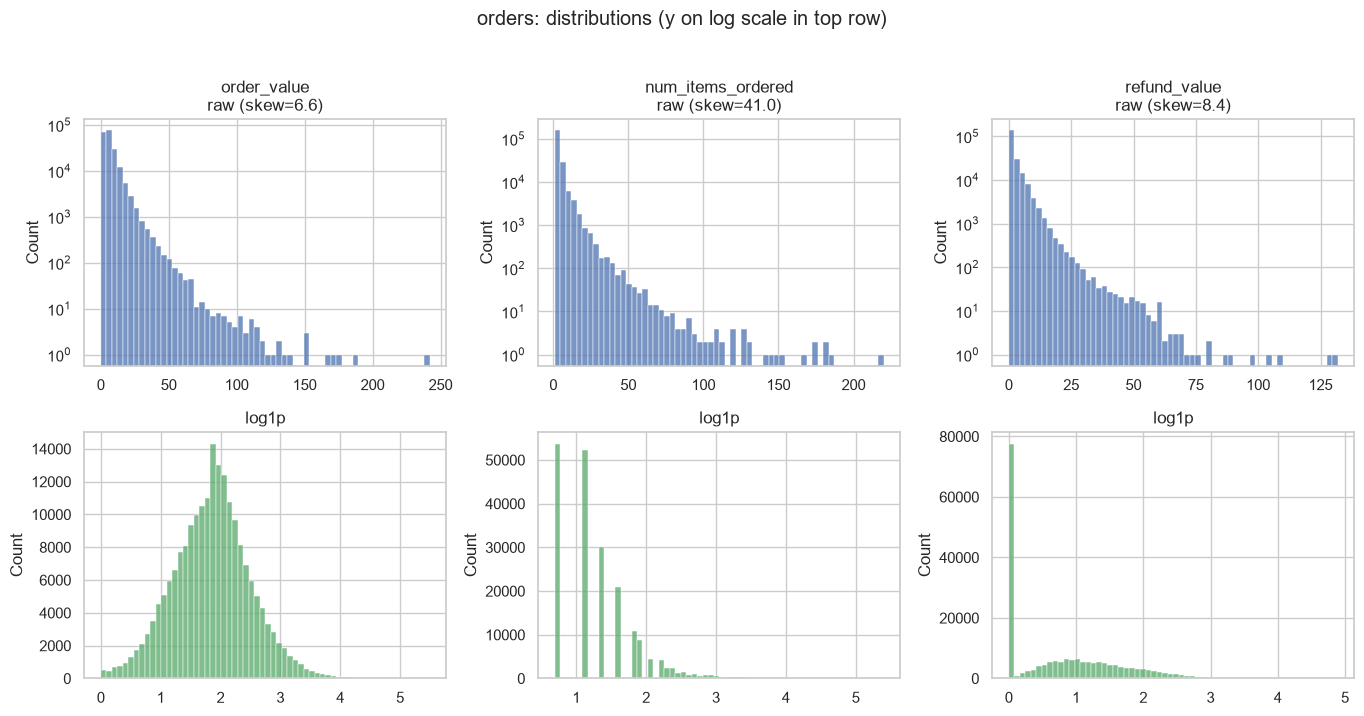

In [12]:
# distributions: raw (shows skew) vs log1p (shows how a transform fixes it)
for t in num:
    cols = NUMERIC[t]
    samp = num[t].sample(min(PLOT_SAMPLE, len(num[t])), random_state=SEED)
    fig, axes = plt.subplots(2, len(cols), figsize=(4.6 * len(cols), 7), squeeze=False)
    for j, c in enumerate(cols):
        x = samp[c].dropna()
        sk = summary.query("table==@t and column==@c")["skew"].iloc[0]
        sns.histplot(x, bins=60, ax=axes[0, j], color="#4C72B0")
        axes[0, j].set_title(f"{c}\nraw (skew={sk:.1f})"); axes[0, j].set_yscale("log"); axes[0, j].set_xlabel("")
        sns.histplot(np.log1p(x.clip(lower=0)), bins=60, ax=axes[1, j], color="#55A868")
        axes[1, j].set_title("log1p"); axes[1, j].set_xlabel("")
    fig.suptitle(f"{t}: distributions (y on log scale in top row)", y=1.02)
    savefig(f"03_numeric_hist_{t}")

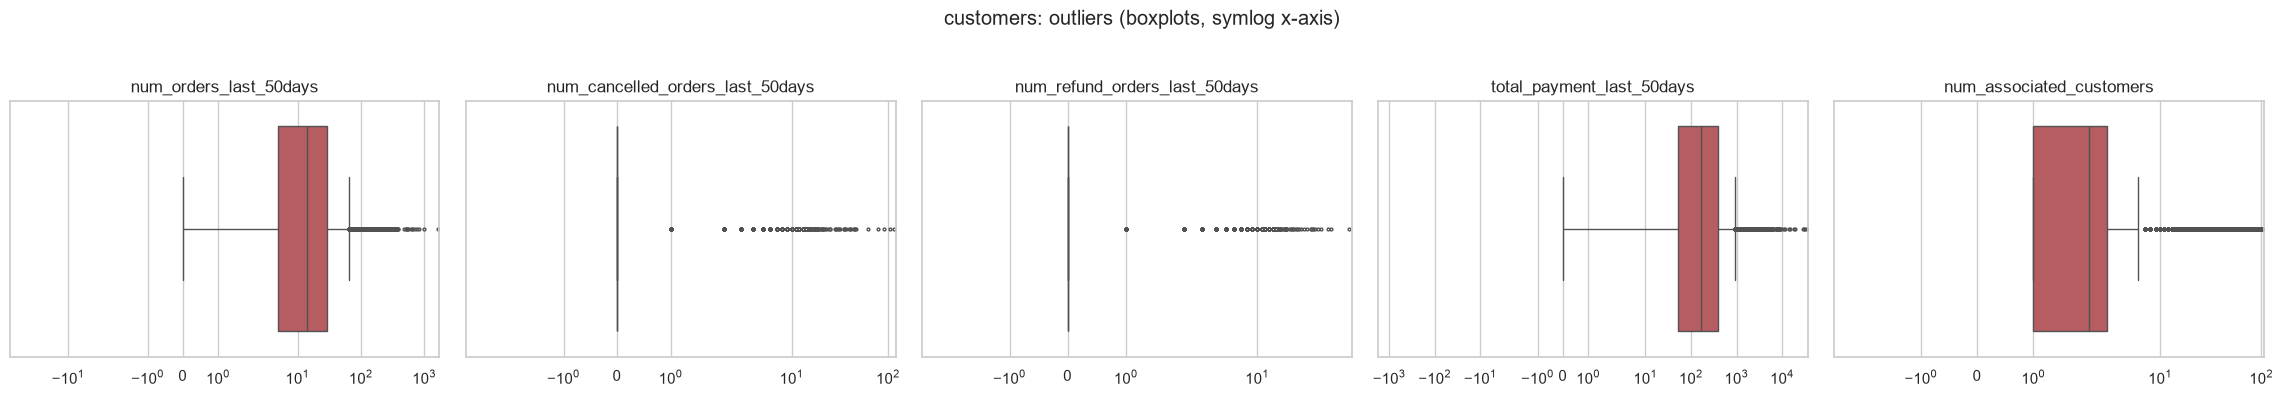

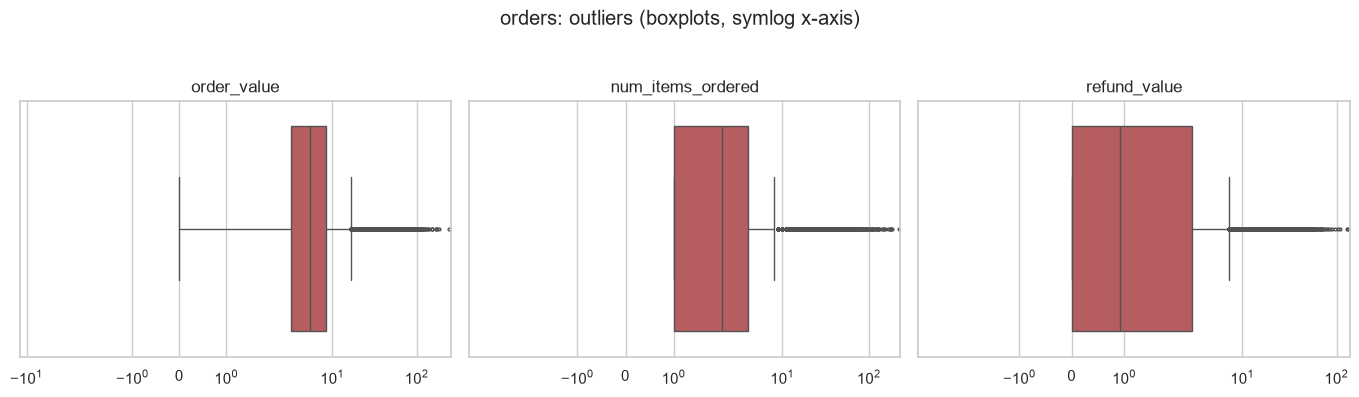

In [13]:
# boxplots (symlog axis so both the bulk and the extreme points are visible)
for t in num:
    cols = NUMERIC[t]
    samp = num[t].sample(min(PLOT_SAMPLE, len(num[t])), random_state=SEED)
    fig, axes = plt.subplots(1, len(cols), figsize=(4.6 * len(cols), 3.8), squeeze=False)
    for j, c in enumerate(cols):
        sns.boxplot(x=samp[c].dropna(), ax=axes[0, j], color="#C44E52", fliersize=2)
        axes[0, j].set_xscale("symlog"); axes[0, j].set_title(c); axes[0, j].set_xlabel("")
    fig.suptitle(f"{t}: outliers (boxplots, symlog x-axis)", y=1.04)
    savefig(f"03_numeric_box_{t}")

### 3a · Business-rule (logical consistency) checks
Values can be numeric and still impossible. Each rule below comes from what the column *means* in Appendix A1.

In [14]:
c, o = num["customers"], num["orders"]
rules = [
    ("customers", "num_cancelled_orders_last_50days", "cancelled orders > total orders in last 50 days",
     (c.num_cancelled_orders_last_50days > c.num_orders_last_50days), len(c)),
    ("customers", "num_refund_orders_last_50days", "refund orders > total orders in last 50 days",
     (c.num_refund_orders_last_50days > c.num_orders_last_50days), len(c)),
    ("customers", "total_payment_last_50days", "paid money but 0 orders in last 50 days",
     ((c.total_payment_last_50days > 0) & (c.num_orders_last_50days == 0)), len(c)),
    ("customers", "num_orders_last_50days", "non-integer or negative count",
     ((c.num_orders_last_50days < 0) | (c.num_orders_last_50days % 1 != 0)), len(c)),
    ("orders", "refund_value", "refund_value > order_value (refund more than was paid)",
     (o.refund_value > o.order_value), len(o)),
    ("orders", "order_value", "order_value <= 0",
     (o.order_value <= 0), len(o)),
    ("orders", "num_items_ordered", "num_items_ordered < 1 or non-integer",
     ((o.num_items_ordered < 1) | (o.num_items_ordered % 1 != 0)), len(o)),
]
rows = []
for t, col, desc, mask, n in rules:
    k = int(mask.sum()); rows.append(dict(table=t, column=col, rule_violated=desc, rows=k, pct=100 * k / n))
    if k:
        # Review of PR #112: per-rule fixes instead of blanket NaN/cap.
        # refund>order looks like how refunds are recorded (keep raw, flag, exclude leakage col);
        # paid-but-0-orders may be legitimate settlement of an earlier order (investigate, don't modify).
        per_rule_fix = {
            "refund_value > order_value": (
                "Keep the raw value in RDS; flag only; exclude refund_value from model features (leakage, see 4f)",
                "Looks like how refunds are recorded, not broken data; excluding it protects analytics (IND-01)",
                "Low"),
            "paid money but 0 orders": (
                "Investigate with the Operations team; don't modify",
                "Payment may relate to an order placed earlier and settled within the window, so it may not be impossible",
                "Medium"),
        }
        fix, impact, sev = next((v for kk, v in per_rule_fix.items() if kk in desc),
                                ("Set violating values to NaN (or cap) and log the count in cleaning.py",
                                 "Impossible values mislead the model", "Medium"))
        log_issue(f"Rule violated: {desc}", t, col, k, n, fix, impact, sev)
pd.DataFrame(rows)

,table,column,rule_violated,rows,pct
0,customers,num_cancelled_orders_last_50days,cancelled orders > total orders in last 50 days,0,0.000
1,customers,num_refund_orders_last_50days,refund orders > total orders in last 50 days,0,0.000
2,customers,total_payment_last_50days,paid money but 0 orders in last 50 days,28556,3.168
3,customers,num_orders_last_50days,non-integer or negative count,0,0.000
4,orders,refund_value,refund_value > order_value (refund more than w...,199687,21.022
5,orders,order_value,order_value <= 0,23,0.002
6,orders,num_items_ordered,num_items_ordered < 1 or non-integer,1,0.000


### 3b · Dates – how many formats?
The team sheet says dates may arrive in **two formats**. Replacing every digit with `9` and every letter with `a` turns each value into a *shape* (`9999-99-99 99:99:99`), and counting shapes reveals the formats without guessing.

In [15]:
def date_signature(s):
    return s.dropna().str.strip().str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]", "a", regex=True)

for t, col in [("orders", "order_date"), ("customers", "first_order_datetime")]:
    print(f"\n##### {t}.{col} – shapes of the raw strings")
    display(date_signature(raw[t][col]).value_counts().to_frame("rows"))


##### orders.order_date – shapes of the raw strings


,rows
order_date,
9999/99/99,949180
9999/aaa/99,509
9999-99-99,200



##### customers.first_order_datetime – shapes of the raw strings


,rows
first_order_datetime,
9999-99-99 99:99:99,900600


In [16]:
# Edit this list after looking at the shapes above. Order matters: most specific first.
DATE_FORMATS = ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M", "%Y-%m-%d", "%Y/%m/%d", "%Y/%b/%d", "%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M", "%d/%m/%Y"]

def parse_mixed_dates(s, formats=DATE_FORMATS):
    """Try each explicit format on what is still unparsed. Returns (datetime Series, {format: rows parsed})."""
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    used = {}
    todo = s.notna()
    for f in formats:
        idx = s.index[todo & out.isna()]
        if len(idx) == 0:
            break
        p = pd.to_datetime(s.loc[idx].str.strip(), format=f, errors="coerce")
        ok = p.notna()
        out.loc[idx[ok]] = p[ok]
        used[f] = int(ok.sum())
    return out, used

dates = {}
for t, col in [("orders", "order_date"), ("customers", "first_order_datetime")]:
    parsed, used = parse_mixed_dates(raw[t][col])
    dates[(t, col)] = parsed
    unparsed = int((parsed.isna() & raw[t][col].notna()).sum())
    print(f"{t}.{col}: parsed by format -> {used} | unparseable: {unparsed:,}")
    n_formats = sum(v > 0 for v in used.values())
    if n_formats > 1:
        log_issue(f"Dates arrive in {n_formats} different formats", t, col,
                  sum(v for f, v in used.items() if f != max(used, key=used.get)), len(raw[t]),
                  "Parse with explicit format list (parse_mixed_dates) -> one datetime64 column",
                  "String dates cannot be used for time features (account age, hour, weekday)", "High")
    if unparsed:
        log_issue("Unparseable date strings", t, col, unparsed, len(raw[t]), "Set to NaT and log", "Missing time features", "Medium")
    now = pd.Timestamp.now()
    fut = int((parsed > now).sum())
    if fut:
        log_issue("Dates in the future", t, col, fut, len(raw[t]), "Set to NaT (or cap at extraction date)", "Negative account age / impossible timing", "Medium")

orders.order_date: parsed by format -> {'%Y-%m-%d %H:%M:%S': 0, '%Y-%m-%d %H:%M': 0, '%Y-%m-%d': 200, '%Y/%m/%d': 949180, '%Y/%b/%d': 509} | unparseable: 0


customers.first_order_datetime: parsed by format -> {'%Y-%m-%d %H:%M:%S': 900600} | unparseable: 0


In [17]:
# dd/mm vs mm/dd ambiguity check: test whether middle or last component represents day/month
for t, col in [("orders", "order_date"), ("customers", "first_order_datetime")]:
    ex_dmy = raw[t][col].dropna().str.extract(r"^(\d{1,2})/(\d{1,2})/").dropna().astype(int)
    ex_ymd = raw[t][col].dropna().str.extract(r"^\d{4}/(\d{1,2})/(\d{1,2})").dropna().astype(int)
    if len(ex_dmy):
        print(f"{t}.{col}: slash-dates={len(ex_dmy):,}  max(first part)={ex_dmy[0].max()}  max(second part)={ex_dmy[1].max()}"
              f"  -> {'dd/mm/yyyy' if ex_dmy[0].max() > 12 and ex_dmy[1].max() <= 12 else 'CHECK: ambiguous or mm/dd'}")
    elif len(ex_ymd):
        print(f"{t}.{col}: slash-dates (YYYY/...)= {len(ex_ymd):,}  max(part 1)={ex_ymd[0].max()}  max(part 2)={ex_ymd[1].max()}"
              f"  -> {'YYYY/MM/DD' if ex_ymd[1].max() > 12 and ex_ymd[0].max() <= 12 else 'CHECK: ambiguous'}")
    else:
        print(f"{t}.{col}: no slash-style dates")

orders.order_date: slash-dates (YYYY/...)= 949,180  max(part 1)=12  max(part 2)=31  -> YYYY/MM/DD


customers.first_order_datetime: no slash-style dates


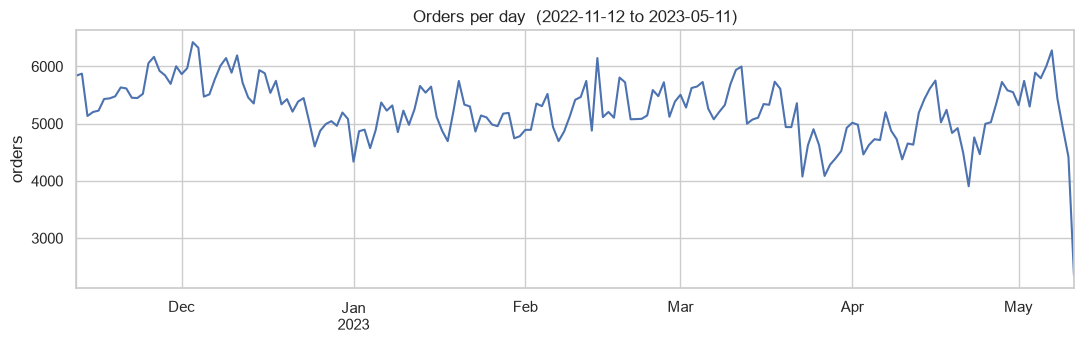

In [18]:
# time coverage: when were the orders placed? (new batches should look similar, or the model faces drift)
od = dates[("orders", "order_date")].dropna()
if len(od):
    fig, ax = plt.subplots(figsize=(11, 3.6))
    od.dt.floor("D").value_counts().sort_index().plot(ax=ax, color="#4C72B0")
    ax.set_title(f"Orders per day  ({od.min():%Y-%m-%d} to {od.max():%Y-%m-%d})"); ax.set_ylabel("orders"); ax.set_xlabel("")
    savefig("03_orders_per_day")

## 4 · PBI-02.4 – Fraud class balance and join coverage

### 4a · Target balance
Only ~11% of orders are fraud. **Why it matters:** a model that predicts "not fraud" for everything is ~89% accurate yet catches **zero** fraud. So accuracy is useless here; we need precision, recall, F1 and PR-AUC (matches PBI-07 acceptance criteria), plus imbalance handling (class weights / resampling, PBI-04.5).

is_fraud values outside {0,1} or non-numeric: 0


,orders,pct
is_fraud,,
0,845814,89.003
1,104504,10.997


Fraud rate = 11.00%   |   imbalance ratio = 8.1 : 1   |   'always predict 0' accuracy = 89.0%


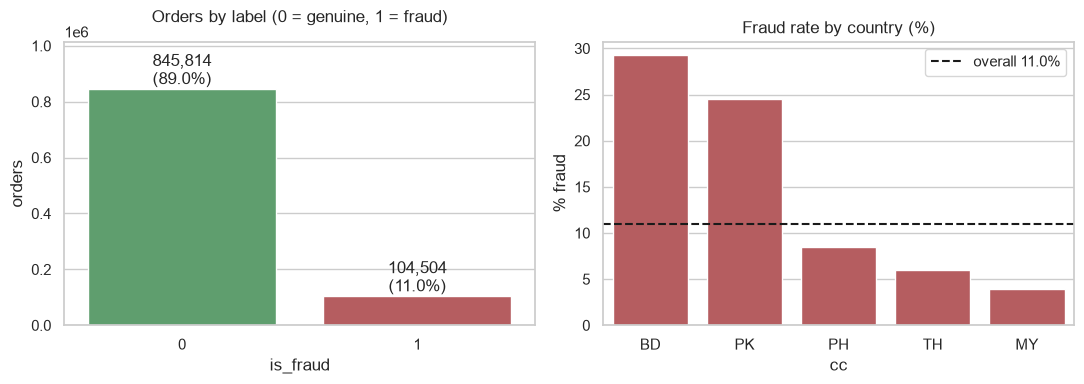

,fraud_rate,orders
cc,,
BD,0.293,59564
PK,0.245,184840
PH,0.085,281419
TH,0.060,63788
MY,0.039,360707


In [19]:
lab = raw["labels"]
y_raw = lab["is_fraud"]
y = pd.to_numeric(y_raw, errors="coerce")
invalid_y = int((~y.isin([0, 1])).sum())
print(f"is_fraud values outside {{0,1}} or non-numeric: {invalid_y:,}")
if invalid_y:
    log_issue("is_fraud contains values other than 0/1", "labels", "is_fraud", invalid_y, len(lab),
              "Drop those rows from training and log", "Corrupt target", "High")

bal = y.value_counts().sort_index().to_frame("orders")
bal["pct"] = 100 * bal.orders / bal.orders.sum()
display(bal)
fraud_rate = float(y.mean()); ratio = (1 - fraud_rate) / fraud_rate
print(f"Fraud rate = {100*fraud_rate:.2f}%   |   imbalance ratio = {ratio:.1f} : 1   |   'always predict 0' accuracy = {100*(1-fraud_rate):.1f}%")
log_issue(f"Class imbalance: fraud = {100*fraud_rate:.1f}% of orders ({ratio:.1f}:1)", "labels", "is_fraud",
          int(y.sum()), len(lab), "class_weight / scale_pos_weight or resampling (train set only); evaluate with PR-AUC, recall, precision, F1; stratified split",
          "Accuracy is misleading; model biased to majority class", "High")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=bal.index.astype(int).astype(str), y=bal.orders, ax=axes[0], palette=["#55A868", "#C44E52"], hue=bal.index.astype(int).astype(str), legend=False)
axes[0].set_title("Orders by label (0 = genuine, 1 = fraud)", pad=14); axes[0].set_xlabel("is_fraud"); axes[0].set_ylim(0, bal.orders.max() * 1.2)
for i, v in enumerate(bal.orders): axes[0].text(i, v, f"{v:,}\n({bal.pct.iloc[i]:.1f}%)", ha="center", va="bottom")
fr_c = pd.DataFrame({"cc": lab["cc"], "y": y}).groupby("cc").y.agg(["mean", "size"]).sort_values("mean", ascending=False)
sns.barplot(x=fr_c.index, y=100 * fr_c["mean"], ax=axes[1], color="#C44E52")
axes[1].axhline(100 * fraud_rate, ls="--", color="k", label=f"overall {100*fraud_rate:.1f}%"); axes[1].legend()
axes[1].set_title("Fraud rate by country (%)"); axes[1].set_ylabel("% fraud")
savefig("04_class_balance")
display(fr_c.rename(columns={"mean": "fraud_rate", "size": "orders"}))

### 4b · One customer, many orders (affects how we split train/test)
If the same customer appears in both train and test, the model can "memorise" the customer and scores look better than reality. We measure how concentrated orders and fraud are across customers.

customers: 622,272 | with >1 order: 24.8% | max orders by one customer: 125
share of all fraud orders coming from the top 1% of customers: 25.3%


,orders,frauds
cust,,
MY|e28fa6f56f,61,57
MY|ebc22b1dcc,112,54
PK|c0f1327473,75,46
PK|02d369ea9e,64,44
MY|67f791f9b1,71,43
MY|4c9d4e054d,83,42
MY|fa69b95123,41,41
MY|1d7e82e5fc,80,38
MY|59264c9c56,79,36


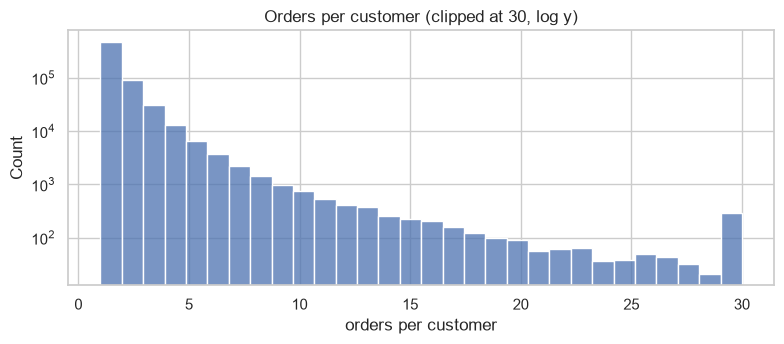

In [20]:
cu = pd.DataFrame({"cust": lab["cc"] + "|" + lab["customer_id"], "y": y})
per = cu.groupby("cust").y.agg(orders="size", frauds="sum")
print(f"customers: {len(per):,} | with >1 order: {100*(per.orders>1).mean():.1f}% | max orders by one customer: {per.orders.max()}")
repeat = int((per.orders > 1).sum())
log_issue("Customers place several orders (same customer in train & test would leak)", "labels", "customer_id", repeat, len(per),
          "Split by customer (GroupShuffleSplit / GroupKFold) not by row", "Optimistic evaluation if customers leak across the split", "High")
top = per.sort_values("frauds", ascending=False)
print(f"share of all fraud orders coming from the top 1% of customers: {100*top.frauds.head(max(1,len(per)//100)).sum()/per.frauds.sum():.1f}%")
display(top.head(10))
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(per.orders.clip(upper=30), bins=30, ax=ax, color="#4C72B0"); ax.set_yscale("log")
ax.set_title("Orders per customer (clipped at 30, log y)"); ax.set_xlabel("orders per customer")
savefig("04_orders_per_customer")

### 4c · Join coverage
`orders` has **no `customer_id`** – the `labels` table is the bridge:
`customers —(country_code, customer_id)— labels —(country_code, order_id)— orders`.
We test (i) how many rows find a partner, and (ii) what happens if you join on `order_id` alone.

,left_rows,matched,unmatched,pct_matched
relationship,,,,
labels -> orders (order key),950318,949874,444,99.953
orders -> labels (order key),949889,949874,15,99.998
labels -> customers (customer key),950318,950304,14,99.999
customers -> labels (customer key),901312,622258,279054,69.039


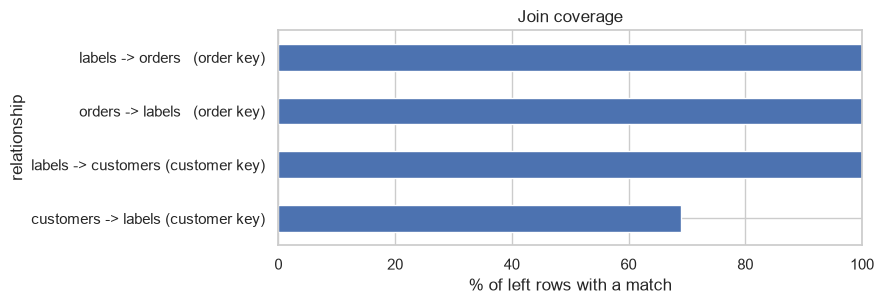

In [21]:
ords, cus = raw["orders"], raw["customers"]
for df, idc in [(lab, "order_id"), (ords, "order_id")]:
    df["k_order"] = df["cc"] + "|" + df[idc]
lab["k_cust"] = lab["cc"] + "|" + lab["customer_id"]
cus["k_cust"] = cus["cc"] + "|" + cus["customer_id"]

pairs = [
    ("labels -> orders   (order key)",   lab["k_order"].isin(set(ords["k_order"])), "labels", "order_id"),
    ("orders -> labels   (order key)",   ords["k_order"].isin(set(lab["k_order"])), "orders", "order_id"),
    ("labels -> customers (customer key)", lab["k_cust"].isin(set(cus["k_cust"])), "labels", "customer_id"),
    ("customers -> labels (customer key)", cus["k_cust"].isin(set(lab["k_cust"])), "customers", "customer_id"),
]
rows = []
for name, m, t, col in pairs:
    n = len(m); k = int((~m).sum())
    rows.append(dict(relationship=name, left_rows=n, matched=int(m.sum()), unmatched=k, pct_matched=100 * m.mean()))
    if k:
        log_issue(f"Join coverage gap: {name}", t, col, k, n,
                  "Decide: inner join (drop unmatched) for training; keep + flag for scoring; investigate with Operations team",
                  "Unmatched rows have no features (NaN) or no label", "High" if k / n > 0.05 else "Medium")
cov = pd.DataFrame(rows).set_index("relationship")
display(cov)
fig, ax = plt.subplots(figsize=(9, 3.2))
cov["pct_matched"].iloc[::-1].plot.barh(ax=ax, color="#4C72B0"); ax.set_xlim(0, 100)
ax.set_xlabel("% of left rows with a match"); ax.set_title("Join coverage")
savefig("04_join_coverage")

In [22]:
# What goes wrong if we join on order_id ONLY (ignoring country)?
left = lab[["order_id", "cc"]]
right = ords[["order_id", "cc"]].drop_duplicates()
id_only = left.merge(right, on="order_id", how="left", suffixes=("", "_ord"))
fan_out = len(id_only) - len(left)
wrong_country = int(((id_only["cc"] != id_only["cc_ord"]) & id_only["cc_ord"].notna()).sum())
print(f"labels rows: {len(left):,} -> after id-only join: {len(id_only):,}  (extra rows: {fan_out:,})")
print(f"matches whose country differs (a DIFFERENT order was attached): {wrong_country:,}")
if fan_out or wrong_country:
    log_issue("Joining on order_id alone creates extra / wrong matches", "labels+orders", "order_id",
              fan_out + wrong_country, len(left), "Always join on [country_code, order_id]", "Wrong features attached to labels", "High")

labels rows: 950,318 -> after id-only join: 950,323  (extra rows: 5)
matches whose country differs (a DIFFERENT order was attached): 6


### 4d · Build an *exploratory* merged table (not the final cleaning – that's PBI-03/04)
Minimal normalisation only, so we can ask: *which columns actually relate to fraud?* This tells PBI-04 where to spend effort and flags **target leakage**.

In [23]:
def to_bool(s):
    t = s.str.strip().str.lower()
    return t.map(lambda v: True if v in TRUE_TOKENS else (False if v in FALSE_TOKENS else np.nan))

L = pd.DataFrame({"cc": lab["cc"], "order_id": lab["order_id"], "customer_id": lab["customer_id"], "is_fraud": y}) \
      .drop_duplicates(["cc", "order_id"])
O = pd.concat([ords[["cc", "order_id"]], canon(ords["collect_type"]).rename("collect_type"),
               canon(ords["payment_method"]).rename("payment_method"), num["orders"],
               dates[("orders", "order_date")].rename("order_date")], axis=1).drop_duplicates(["cc", "order_id"])
C = pd.concat([cus[["cc", "customer_id"]], to_bool(cus["mobile_verified"]).rename("mobile_verified"), num["customers"],
               dates[("customers", "first_order_datetime")].rename("first_order_datetime")], axis=1).drop_duplicates(["cc", "customer_id"])

full = L.merge(O, on=["cc", "order_id"], how="left").merge(C, on=["cc", "customer_id"], how="left")
print("merged shape:", full.shape, "| rows == labels rows (no fan-out):", len(full) == len(L))
full.head()

merged shape: (950318, 17) | rows == labels rows (no fan-out): True


,cc,order_id,customer_id,is_fraud,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,TH,b9ce4cdead,4a2deee064,0,delivery,payment on delivery,13.877,1.000,4.630,2022-12-31,True,1.000,0.000,0.000,22.012,3.000,2019-07-30 13:29:17
1,MY,eae640c3dd,0e39f85e6d,0,delivery,boost wallet,2.512,1.000,3.350,2023-03-27,True,5.000,0.000,0.000,78.427,2.000,2023-03-19 10:39:54
2,PH,6b5eff4d8f,b88034bb7a,0,delivery,payment on delivery,4.309,3.000,0.000,2022-11-16,True,9.000,0.000,0.000,116.873,5.000,2022-07-01 14:51:03
3,MY,31928238a7,b24be37d24,0,delivery,credit card,8.090,1.000,4.500,2023-01-02,True,33.000,1.000,5.000,520.322,1.000,2020-06-07 06:47:20
4,MY,4adec8e335,996287540f,0,delivery,NaN,8.935,2.000,1.740,2023-04-02,True,13.000,0.000,1.000,239.913,1.000,2022-03-15 05:05:32


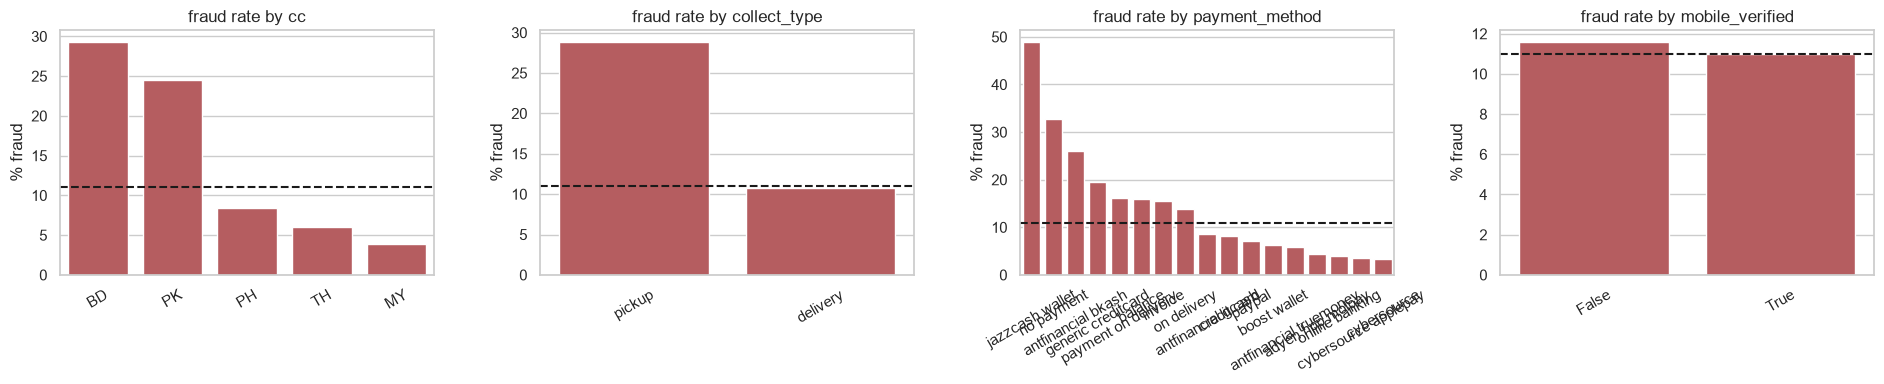

In [24]:
def fraud_rate_by(df, col, min_n=100):
    g = df.groupby(col, dropna=False)["is_fraud"].agg(rows="size", fraud="sum")
    g["fraud_rate_pct"] = 100 * g.fraud / g.rows
    return g[g.rows >= min_n].sort_values("fraud_rate_pct", ascending=False)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col in zip(axes, ["cc", "collect_type", "payment_method", "mobile_verified"]):
    g = fraud_rate_by(full, col)
    sns.barplot(x=g.index.astype(str), y=g.fraud_rate_pct, ax=ax, color="#C44E52")
    ax.axhline(100 * fraud_rate, ls="--", color="k"); ax.set_title(f"fraud rate by {col}"); ax.set_ylabel("% fraud"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
savefig("04_fraud_rate_by_category")

### 4e · Does *missingness* carry signal? (informative missing values)

In [25]:
rows = []
for c in [c for c in full.columns if c not in ("order_id", "customer_id", "is_fraud")]:
    m = full[c].isna()
    if m.any() and (~m).any():
        rows.append(dict(column=c, rows_missing=int(m.sum()), fraud_rate_if_missing=100 * full.loc[m, "is_fraud"].mean(),
                         fraud_rate_if_present=100 * full.loc[~m, "is_fraud"].mean()))
miss_signal = pd.DataFrame(rows).set_index("column") if rows else pd.DataFrame({"result": ["no missing values after merge"]})
display(miss_signal)

,rows_missing,fraud_rate_if_missing,fraud_rate_if_present
column,,,
collect_type,444,18.468,10.993
payment_method,21945,5.204,11.134
order_value,444,18.468,10.993
num_items_ordered,445,18.652,10.993
refund_value,444,18.468,10.993
order_date,444,18.468,10.993
mobile_verified,14,14.286,10.997
num_orders_last_50days,14,14.286,10.997
num_cancelled_orders_last_50days,14,14.286,10.997


### 4f · Numeric features vs fraud, and the **target-leakage** check
Fraud here means *"placed the order, then sought a refund without proper reasons"*. A **refund** column therefore may only exist **after** the outcome is known – but the Trust & Safety team must flag the order **before it ships**. A feature that is not available at prediction time is *target leakage*: it gives brilliant offline scores and useless production behaviour. Below we measure it rather than assume it.

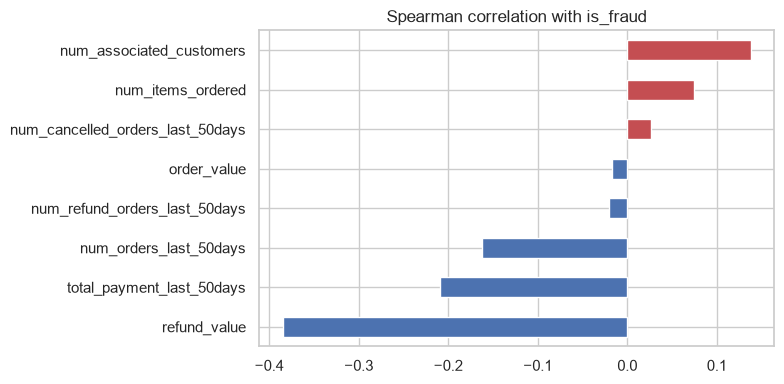

,rows_with_value_gt_0,pct_rows,fraud_rate_if_gt_0,fraud_rate_if_0
feature,,,,
refund_value,581940,61.236,0.000,28.369
num_refund_orders_last_50days,301169,31.691,9.318,11.775


In [26]:
numcols = [c for c in NUMERIC["orders"] + NUMERIC["customers"] if c in full.columns]
samp = full.sample(min(PLOT_SAMPLE, len(full)), random_state=SEED)
sp = samp[numcols].rank().corrwith(samp["is_fraud"].rank()).sort_values()   # Spearman = Pearson on ranks
fig, ax = plt.subplots(figsize=(8, 4))
sp.plot.barh(ax=ax, color=["#C44E52" if v > 0 else "#4C72B0" for v in sp]); ax.set_title("Spearman correlation with is_fraud")
savefig("04_spearman_with_fraud")

leak_rows = []
for col in ["refund_value", "num_refund_orders_last_50days"]:
    if col in full.columns:
        flag = full[col] > 0
        leak_rows.append(dict(feature=col, rows_with_value_gt_0=int(flag.sum()), pct_rows=100 * flag.mean(),
                              fraud_rate_if_gt_0=100 * full.loc[flag, "is_fraud"].mean() if flag.any() else np.nan,
                              fraud_rate_if_0=100 * full.loc[~flag, "is_fraud"].mean()))
leak = pd.DataFrame(leak_rows).set_index("feature"); display(leak)
for col, r in leak.iterrows():
    if r.fraud_rate_if_gt_0 > 3 * 100 * fraud_rate:
        log_issue("Possible target leakage: strongly tied to fraud and likely only known after the order outcome", "orders/customers", col,
                  r.rows_with_value_gt_0, len(full), "Team decision for PBI-04: exclude from the real-time model, or document it as an 'after-the-fact' feature",
                  "Inflated offline metrics; model unusable at pre-shipment time", "High")

## 5 · PBI-02.5 – Data-issue log
One row per issue, **built from the counts computed above** – so every issue is backed by a number (acceptance criterion) and every row names the fix PBI-03/04 must implement.

In [27]:
issue_log = (pd.DataFrame(ISSUES.values())
             .assign(sev_rank=lambda d: d.severity.map({"High": 0, "Medium": 1, "Low": 2}))
             .sort_values(["sev_rank", "pct"], ascending=[True, False]).drop(columns="sev_rank").reset_index(drop=True))
issue_log.insert(0, "id", [f"DI-{i+1:02d}" for i in range(len(issue_log))])
issue_log.to_csv(DOCS_DIR / "data_issue_log.csv", index=False)

def to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v).replace("|", "/") for v in r) + " |" for r in df.itertuples(index=False)]
    return "\n".join(lines)
(DOCS_DIR / "data_issue_log.md").write_text(to_md(issue_log), encoding="utf-8")
print(f"{len(issue_log)} issues logged -> {DOCS_DIR/'data_issue_log.csv'}  (+ .md)")
issue_log

38 issues logged -> ..\docs\data_issue_log.csv  (+ .md)


,id,issue,table,column,count,total_rows,pct,proposed_fix,ml_impact,severity
0,DI-01,Join coverage gap: customers -> labels (custom...,customers,customer_id,279054,901312,30.961,Decide: inner join (drop unmatched) for traini...,Unmatched rows have no features (NaN) or no label,High
1,DI-02,Customers place several orders (same customer ...,labels,customer_id,154380,622272,24.809,Split by customer (GroupShuffleSplit / GroupKF...,Optimistic evaluation if customers leak across...,High
2,DI-03,Class imbalance: fraud = 11.0% of orders (8.1:1),labels,is_fraud,104504,950318,10.997,class_weight / scale_pos_weight or resampling ...,Accuracy is misleading; model biased to majori...,High
3,DI-04,Dates arrive in 3 different formats,orders,order_date,709,949889,0.075,Parse with explicit format list (parse_mixed_d...,String dates cannot be used for time features ...,High
4,DI-05,country_code not upper-case / has whitespace (...,customers,country_code,390,901312,0.043,str.strip().str.upper(),Splits one country into two categories; breaks...,High
5,DI-06,country_code not upper-case / has whitespace (...,labels,country_code,301,950318,0.032,str.strip().str.upper(),Splits one country into two categories; breaks...,High
6,DI-07,mobile_verified is not a clean True/False (mix...,customers,mobile_verified,165,901312,0.018,"Map {true,t,1,yes,y}->True, {false,f,0,no,n}->...",Pandas keeps it as object/str -> encoder error...,High
7,DI-08,Inconsistent spellings / case / whitespace of ...,orders,payment_method,123,949889,0.013,"Normalise: strip, lower-case, map synonyms to ...",Same category split into several one-hot columns,High
8,DI-09,Inconsistent spellings / case / whitespace of ...,orders,collect_type,85,949889,0.009,"Normalise: strip, lower-case, map synonyms to ...",Same category split into several one-hot columns,High
9,DI-10,Joining on order_id alone creates extra / wron...,labels+orders,order_id,11,950318,0.001,"Always join on [country_code, order_id]",Wrong features attached to labels,High


### Summary of findings
* **Quality issues:** All three tables loaded with 0 fully-duplicate rows. Missing values affect two columns: `payment_method` (21,501 rows, 2.26% of orders) and `customers.first_order_datetime` (712 rows, 0.08%). Category columns carry spelling/case variants that must be normalised before one-hot encoding: 165 `'yes'` values in `mobile_verified` (should be `True`), 85 lowercase `'delivery'` in `collect_type`, 123 mixed-case rows in `payment_method`, and lowercase country codes in `customers` (390 rows) and `labels` (301 rows). The composite key `(country_code, order_id)` is mandatory for all joins — joining on `order_id` alone causes 11 cross-country mismatches (DI-10).
* **Distribution issues:** All 8 numeric feature columns are right-skewed (skew range 5.4–55.0); `num_cancelled_orders_last_50days` is the most extreme (skew = 55.0, 86% of rows are zero). A `log1p` transform normalises these distributions well (shown in Section 3 histograms). Additionally, 199,687 orders (21.0%) have `refund_value > order_value`, which is a logical impossibility requiring cleaning in PBI-03.
* **Target:** Fraud is 11.0% of orders (104,504 out of 950,318), giving an 8.1:1 class imbalance. A 'predict-all-genuine' baseline scores 89% accuracy while catching zero fraud — so the model must be evaluated with PR-AUC, recall, precision, and F1 (never raw accuracy). Fraud rates vary strongly by country: BD = 29.3%, PK = 24.5%, PH = 8.5%, TH = 6.0%, MY = 3.9%, confirming that `country_code` is a strong predictive feature.
* **Joins:** The `labels` table is the bridge between `customers` (via `country_code + customer_id`) and `orders` (via `country_code + order_id`). Both joins exceed 99.95% coverage. However, 30.96% of customer records (279,054 of 901,312) have no matching label row and must be excluded from supervised training. The `refund_value` column is a critical target-leakage risk: when `refund_value > 0` the fraud rate drops to exactly 0% — this column is determined after the order outcome and must be excluded from real-time inference features.
* **Hand-off:** Quality issues (case normalisation, missing-value imputation, business-rule violations) → `cleaning.py` (PBI-03). Skew transforms (`log1p`), class-imbalance handling (`scale_pos_weight`), leakage removal, and customer-grouped train/test split (`GroupShuffleSplit`) → `transform.py` (PBI-04) and model training (PBI-07).